# Analiza e dataset-it IMDb Movies

## 1. Hyrje (Background & argumentimi i temës)

Industria e filmit prodhon mijëra tituj çdo vit dhe lë gjurmë të matshme: vlerësime
të audiencës, numra votash, buxhete dhe kohëzgjatje. Këto të dhëna lejojnë të
shqyrtohen pyetje që janë interesante si nga ana **kulturore** ashtu edhe nga ana
**ekonomike**: a është industria më cilësore sot se 50 vjet më parë? A i përkthen
para të shumta në cilësi më të lartë? Cilët zhanre i pëlqen më shumë audienca?

Tema e zgjedhur ka tre arsye kryesore:

1. **Universaliteti** — filmat janë artefakt kulturor i njohur botërisht, kështu
   që rezultatet janë të lexueshme nga çdo audiencë jo-teknike.
2. **Pasuria e dataset-it** — me 24 kolona dhe gati 60,000 rekorde, lejon analiza
   shumë-dimensionale pa nevojë për dataset shtesë.
3. **Vlerat reale të zbrazëta** — më shumë se 90% e rekordeve nuk kanë informacion
   buxheti, gjë që e bën të domosdoshme dhe edukative trajtimin e *missing values*
   me vendime të dokumentuara.

## 2. Përshkrimi i dataset-it

* **Burimi:** paketa `ggplot2movies` për R, mirëmbajtur nga Hadley Wickham; të
  dhënat janë mbledhur nga IMDb.com (Internet Movie Database).
* **Madhësia:** 58,788 rekorde × 24 kolona.
* **Periudha:** 1893 – 2005.
* **Kolonat kryesore:** `title`, `year`, `length` (kohëzgjatja në minuta),
  `budget` (buxheti në USD), `rating` (vlerësimi mesatar 0–10), `votes` (numri i
  votave), `r1`–`r10` (përqindja e votuesve që dhanë vlerësim *k*), `mpaa`
  (kategoria e MPAA: G, PG, PG-13, R, NC-17), dhe shtatë flamuj binarë për
  zhanrin: `Action`, `Animation`, `Comedy`, `Drama`, `Documentary`, `Romance`,
  `Short`. Një film mund të ketë më shumë se një zhanër njëkohësisht.

## 3. Importimi i bibliotekave dhe konfigurimi global

Përdorim **pandas** dhe **numpy** për manipulimin e të dhënave dhe
**matplotlib** për vizualizimet. Paleta e ngjyrave përgatitet një herë e vetme
dhe ripërdoret në të gjitha grafikët për konsistencë vizuale.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

PRIMARY   = "#7B1E2E"  
SECONDARY = "#C9A961" 
ACCENT    = "#2E4057"   
NEUTRAL   = "#5C5552"  
TEXT_DARK = "#1F1F1F"


GENRE_PALETTE = {
    "Action":      "#7B1E2E",
    "Comedy":      "#C9A961",
    "Drama":       "#2E4057",
    "Romance":     "#A0526D",
    "Animation":   "#3A7D7B",
    "Documentary": "#5C5552",
    "Short":       "#8B7355",
}

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#888888",
    "legend.frameon": False,
    "figure.facecolor": "white",
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

GENRE_COLS = ["Action", "Animation", "Comedy", "Drama",
              "Documentary", "Romance", "Short"]

## 4. Ngarkimi dhe eksplorimi fillestar

Dataset-i është ruajtur si `movies_imdb.csv` në direktoriumin e projektit.

In [2]:
movies_raw = pd.read_csv("movies_imdb.csv")

print(f"Forma e dataset-it: {movies_raw.shape[0]:,} rekorde × {movies_raw.shape[1]} kolona")
movies_raw.head()

Forma e dataset-it: 58,788 rekorde × 24 kolona


,title,year,length,budget,rating,votes,r1,r2,r3,r4,...,r9,r10,mpaa,Action,Animation,Comedy,Drama,Documentary,Romance,Short
0,$,1971,121,NaN,6.4,348,4.5,4.5,4.5,4.5,...,4.5,4.5,NaN,0,0,1,1,0,0,0
1,$1000 a Touchdown,1939,71,NaN,6.0,20,0.0,14.5,4.5,24.5,...,4.5,14.5,NaN,0,0,1,0,0,0,0
2,$21 a Day Once a Month,1941,7,NaN,8.2,5,0.0,0.0,0.0,0.0,...,24.5,24.5,NaN,0,1,0,0,0,0,1
3,"$40,000",1996,70,NaN,8.2,6,14.5,0.0,0.0,0.0,...,34.5,45.5,NaN,0,0,1,0,0,0,0
4,"$50,000 Climax Show, The",1975,71,NaN,3.4,17,24.5,4.5,0.0,14.5,...,0.0,24.5,NaN,0,0,0,0,0,0,0


In [3]:
# Column types
movies_raw.dtypes

title              str
year             int64
length           int64
budget         float64
rating         float64
votes            int64
r1             float64
r2             float64
r3             float64
r4             float64
r5             float64
r6             float64
r7             float64
r8             float64
r9             float64
r10            float64
mpaa               str
Action           int64
Animation        int64
Comedy           int64
Drama            int64
Documentary      int64
Romance          int64
Short            int64
dtype: object

In [4]:
# Permbledhje
movies_raw[["year", "length", "budget", "rating", "votes"]].describe()

,year,length,budget,rating,votes
count,58788.000000,58788.000000,5.215000e+03,58788.000000,58788.000000
mean,1976.133582,82.337875,1.341251e+07,5.932850,632.130384
std,23.735125,44.347717,2.335008e+07,1.553031,3829.621413
min,1893.000000,1.000000,0.000000e+00,1.000000,5.000000
25%,1958.000000,74.000000,2.500000e+05,5.000000,11.000000
50%,1983.000000,90.000000,3.000000e+06,6.100000,30.000000
75%,1997.000000,100.000000,1.500000e+07,7.000000,112.000000
max,2005.000000,5220.000000,2.000000e+08,10.000000,157608.000000


## 5. Pastrimi i të dhënave dhe trajtimi i vlerave pn.NA

### 5.1 Pasqyra e mungesës

E para — të shohim sa vlera mungojnë në çdo kolonë.

In [5]:
# Numri dhe përqindja e vlerave boshe për çdo kolonë
missing_summary = pd.DataFrame({
    "n_missing": movies_raw.isna().sum(),
    "pct_missing": (movies_raw.isna().mean() * 100).round(2),
})
missing_summary[missing_summary["n_missing"] > 0]

,n_missing,pct_missing
budget,53573,91.13
mpaa,53864,91.62


### 5.2 Vendimet për trajtimin e mungesës

Dy kolona kanë mungesë të lartë: `budget` (~91%) dhe `mpaa` (~92%). **Imputimi nuk
është i përshtatshëm** sepse:

* Mungesa nuk është rastësore: buxheti dhe MPAA mungojnë sistematikisht për
  filma të vjetër, dokumentarë, prodhime të pavarura dhe filma jashtë SHBA-së.
* Imputimi (p.sh. me medianën) do të krijonte vlera fiktive që do të shtremberonin
  analizat ekonomike.

**Vendimi i marrë:** përdorim një **strategji të filtrimit selektiv**. Të dhënat
mbahen të paprekura në dataset-in kryesor, por çdo pyetje analitike filtron
*vetëm rekordet që ka nevojë*. Kjo ruan transparencën e madhësisë së kampionit
për çdo analizë.

Veçanërisht, vlerat `budget == 0` (32 rekorde) **nuk kanë kuptim financiar** dhe
i trajtojmë si të humbura.

### 5.3 Krijimi i kolonave të derivuara

Për të lehtësuar analizat, shtojmë disa kolona të derivuara:

| Kolona             | Kuptimi                                                          |
|--------------------|------------------------------------------------------------------|
| `decade`           | Dekada e prodhimit (1970, 1980, ...) — e dobishme për agregime  |
| `log_budget`       | log₁₀ i buxhetit — shpërndarja origjinale është fortë e zhdrejtë |
| `primary_genre`    | Zhanri i parë i shënuar — për ndarje në grupe ekskluzive          |
| `polarization`     | Indeks që mat sa polarizuese është një film (shih §9)             |

In [ ]:

df = movies_raw.copy()

df.loc[df["budget"] == 0, "budget"] = np.nan


df["decade"] = (df["year"] // 10 * 10).astype(int)


df["log_budget"] = np.log10(df["budget"].where(df["budget"] > 0))


def first_genre(row):
    for g in GENRE_COLS:
        if row[g] == 1:
            return g
    return "Untagged"

df["primary_genre"] = df[GENRE_COLS].apply(first_genre, axis=1)


df["pct_extreme"] = df["r1"] + df["r2"] + df["r9"] + df["r10"]
df["pct_middle"]  = df["r5"] + df["r6"]
df["polarization"] = df["pct_extreme"] / (df["pct_middle"] + 1)

print(f"Dataset i pastruar: {df.shape[0]:,} rekorde × {df.shape[1]} kolona")
print(f"Filma me buxhet të vlefshëm: {df['budget'].notna().sum():,}")
print(f"Filma me kategori MPAA: {df['mpaa'].notna().sum():,}")

Dataset i pastruar: 58,788 rekorde × 30 kolona
Filma me buxhet të vlefshëm: 5,183
Filma me kategori MPAA: 4,924


### 5.4 Pamja vizuale e dataset-it pas pastrimit

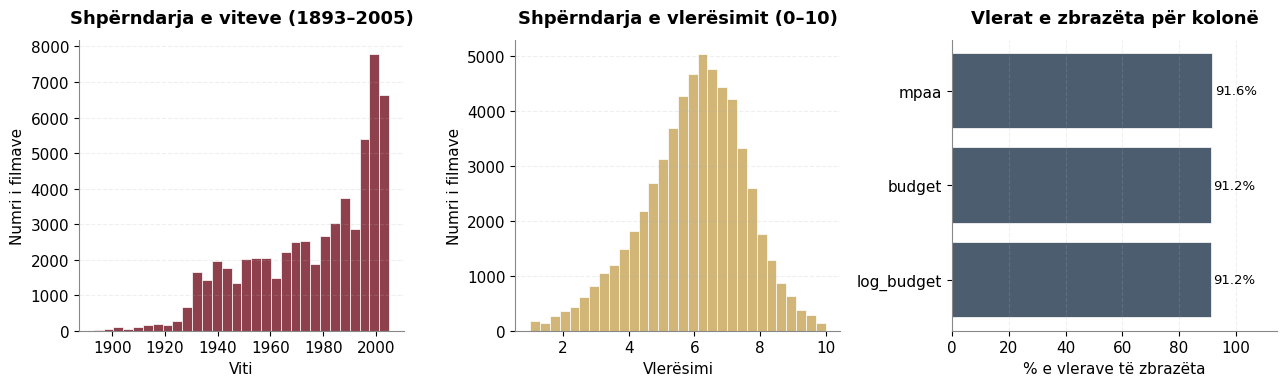

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Shpërndarja e viteve
ax = axes[0]
ax.hist(df["year"], bins=30, color=PRIMARY, alpha=0.85,
        edgecolor="white", linewidth=0.6)
ax.set_title("Shpërndarja e viteve (1893–2005)")
ax.set_xlabel("Viti"); ax.set_ylabel("Numri i filmave")
ax.grid(axis="y", alpha=0.2, linestyle="--")

# Shpërndarja e vlerësimit
ax = axes[1]
ax.hist(df["rating"], bins=30, color=SECONDARY, alpha=0.85,
        edgecolor="white", linewidth=0.6)
ax.set_title("Shpërndarja e vlerësimit (0–10)")
ax.set_xlabel("Vlerësimi"); ax.set_ylabel("Numri i filmave")
ax.grid(axis="y", alpha=0.2, linestyle="--")

# % e vlerave të mungesës
ax = axes[2]
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
ax.barh(miss.index[::-1], miss.values[::-1],
        color=ACCENT, alpha=0.85, edgecolor="white", linewidth=0.6)
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9.5)
ax.set_xlim(0, max(miss.values) * 1.25)
ax.set_xlabel("% e vlerave të zbrazëta")
ax.set_title("Vlerat e zbrazëta për kolonë")
ax.grid(axis="x", alpha=0.2, linestyle="--")

plt.tight_layout()
plt.show()

## 6. Pyetja 1 — Si ka evoluar industria e filmit ndër dekada?

**Pyetja e plotë:** Si kanë ndryshuar prej dekadës 1920 deri në 2000 (a) numri i
filmave të prodhuar, (b) kohëzgjatja mesatare, (c) vlerësimi mesatar i
audiencës, dhe (d) buxheti mesatar?

**Kolonat e përfshira:** `year`, `length`, `rating`, `budget`, `title` (numërimi).

**Strategjia analitike:**

1. Përjashtojmë dekadat para 1920 (fillimi i kinemasë me zë) dhe pas 2000
   sepse dekada 2000 është e papërfunduar në dataset (vetëm 5 vite: 2000–2005).
2. Grupojmë sipas `decade` dhe llogarisim agregatet përkatëse.
3. Përdorim **medianën** për buxhetin (jo mesataren) sepse shpërndarja e tij
   është fortë e zhdrejtë — pak filma blockbuster do ta zhvendosnin mesataren.

In [ ]:

df_q1 = df[df["decade"].between(1920, 2000)].copy()

# Agregimi sipas dekadës — 4 metrika kryesore
by_decade = df_q1.groupby("decade").agg(
    n_films       = ("title",  "size"),
    avg_length    = ("length", "mean"),
    avg_rating    = ("rating", "mean"),
    median_budget = ("budget", "median"),
).reset_index()

by_decade.round(2)

,decade,n_films,avg_length,avg_rating,median_budget
0,1920,795,66.91,6.81,430290.0
1,1930,4328,62.47,6.21,475826.0
2,1940,4613,68.94,6.39,1200000.0
3,1950,5160,78.22,6.10,960000.0
4,1960,5456,88.31,5.88,1100000.0
5,1970,6270,94.46,5.64,1500000.0
6,1980,7907,94.25,5.62,6000000.0
7,1990,12788,87.12,5.64,11000000.0
8,2000,10789,78.26,6.27,3500000.0


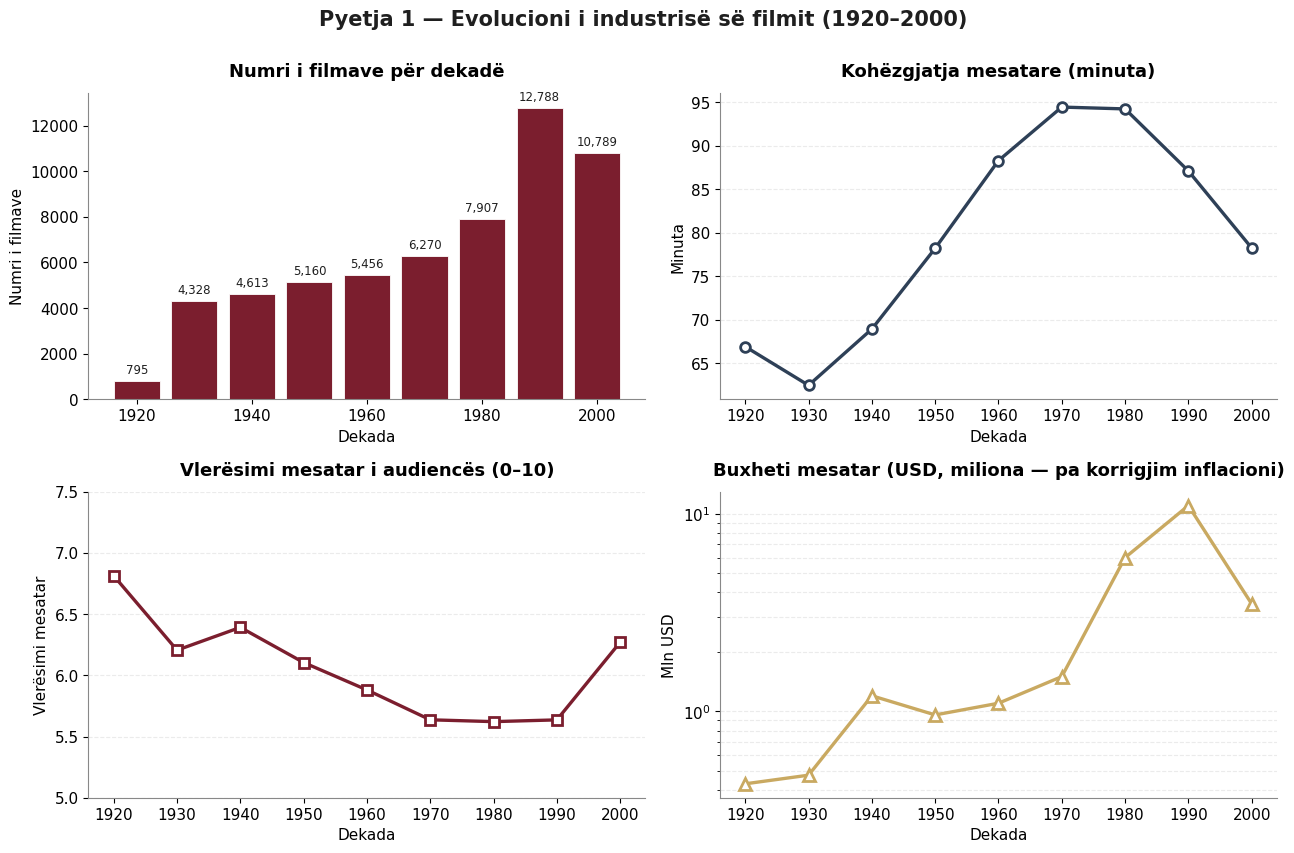

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
fig.suptitle("Pyetja 1 — Evolucioni i industrisë së filmit (1920–2000)",
             fontsize=15, fontweight="bold", color=TEXT_DARK, y=1.00)

# numri i filmave 
ax = axes[0, 0]
ax.bar(by_decade["decade"], by_decade["n_films"],
       width=8, color=PRIMARY, edgecolor="white", linewidth=0.6)
ax.set_title("Numri i filmave për dekadë")
ax.set_xlabel("Dekada"); ax.set_ylabel("Numri i filmave")
for x, y in zip(by_decade["decade"], by_decade["n_films"]):
    ax.text(x, y + max(by_decade["n_films"]) * 0.015, f"{y:,}",
            ha="center", va="bottom", fontsize=8.5, color=TEXT_DARK)

# kohëzgjatja mesatare
ax = axes[0, 1]
ax.plot(by_decade["decade"], by_decade["avg_length"],
        marker="o", color=ACCENT, linewidth=2.4,
        markersize=7, markerfacecolor="white",
        markeredgecolor=ACCENT, markeredgewidth=2)
ax.set_title("Kohëzgjatja mesatare (minuta)")
ax.set_xlabel("Dekada"); ax.set_ylabel("Minuta")
ax.grid(axis="y", alpha=0.25, linestyle="--")

# vlerësimi mesatar
ax = axes[1, 0]
ax.plot(by_decade["decade"], by_decade["avg_rating"],
        marker="s", color=PRIMARY, linewidth=2.4,
        markersize=7, markerfacecolor="white",
        markeredgecolor=PRIMARY, markeredgewidth=2)
ax.set_title("Vlerësimi mesatar i audiencës (0–10)")
ax.set_xlabel("Dekada"); ax.set_ylabel("Vlerësimi mesatar")
ax.set_ylim(5.0, 7.5)
ax.grid(axis="y", alpha=0.25, linestyle="--")

# buxheti mesatar (log scale)
ax = axes[1, 1]
ax.plot(by_decade["decade"], by_decade["median_budget"] / 1e6,
        marker="^", color=SECONDARY, linewidth=2.4,
        markersize=8, markerfacecolor="white",
        markeredgecolor=SECONDARY, markeredgewidth=2)
ax.set_title("Buxheti mesatar (USD, milion)")
ax.set_xlabel("Dekada"); ax.set_ylabel("Mln USD")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.25, linestyle="--", which="both")

plt.tight_layout()
plt.show()

### Interpretimi i Pyetjes 1

* **Vëllimi i prodhimit shpërtheu pas vitit 1980** — nga ~7,900 filma në dekadën
  '80 në mbi 12,700 filma në vitet '90. Kjo lidhet me daljen e DVD-së dhe
  ngritjen e prodhimeve të pavarura dhe televizionit kabllor.
* **Kohëzgjatja u rrit deri në vitet '70–'80** (afër 95 min) dhe më pas u
  shkurtua, ndoshta për shkak të pranisë së gjithnjë e më të madhe të filmave
  të shkurtër (video music, web shorts) që u përfshinë në dataset-in e IMDb.
* **Vlerësimi mesatar ra** nga ~6.8 në vitet '20 në ~5.6 në vitet '70–'90 dhe
  pastaj u rrit përsëri në dekadën 2000. Kjo nuk do të thotë domosdoshmërisht
  që filmat u përkeqsuan; mund të jetë rezultat i ndryshimit të popullsisë së
  audiencës votuese të IMDb (më shumë kritikë në filma të rinj).
* **Buxhetet u rritën në mënyrë eksponenciale** (boshti logaritmik) — nga
  ~$430K në vitet '20 në ~$11M në vitet '90. Pjesërisht inflacion, pjesërisht
  rritje reale e shpenzimeve të prodhimit (efekte speciale, marketing).

## 7. Pyetja 2 — A i garanton një buxhet i lartë vlerësime më të mira?

**Pyetja e plotë:** A ekziston lidhje statistikisht e dukshme midis buxhetit
të një filmi dhe vlerësimit që merr nga audienca? A janë filmat me buxhet të
lartë (>$50M) sistematikisht më të vlerësuar se filmat me buxhet të ulët?

**Kolonat e përfshira:** `budget`, `rating`, `log_budget`, plus `votes` për
filtrim.

**Strategjia analitike:**

1. Filtrojmë vetëm rekordet me buxhet të vlefshëm (5,215 filma).
2. Llogarisim koeficientin e korrelacionit Pearson midis log(buxhetit) dhe
   vlerësimit. Përdorim *log* sepse shpërndarja e buxhetit është fortë
   eksponenciale.
3. Krijojmë katër kategori buxheti (i ulët, mesatar, i lartë, tepër i lartë)
   dhe krahasojmë shpërndarjen e plotë të vlerësimit në çdo grup.

In [10]:
# Filtrimi i rekordeve me buxhet të vlefshëm
sub_q2 = df.dropna(subset=["budget", "rating"]).copy()
sub_q2 = sub_q2[sub_q2["budget"] > 0]

# Kategoritë e buxhetit me kufij të kuptueshëm financiarisht
sub_q2["budget_tier"] = pd.cut(
    sub_q2["budget"],
    bins=[0, 1e6, 1e7, 5e7, np.inf],
    labels=["I ulët\n(<1M)", "Mesatar\n(1–10M)",
            "I lartë\n(10–50M)", "Tepër i lartë\n(>50M)"],
)

# Statistikat përmbledhëse për çdo kategori
tier_stats = sub_q2.groupby("budget_tier", observed=True)["rating"].agg(
    ["count", "mean", "median", "std"]).round(3)
print(tier_stats)

# Koeficienti i korrelacionit Pearson
correlation = sub_q2[["log_budget", "rating"]].corr().iloc[0, 1]
print(f"\nKorrelacioni Pearson (log_budget vs rating): r = {correlation:.4f}")

                       count   mean  median    std
budget_tier                                       
I ulët\n(<1M)           2006  6.197     6.5  1.865
Mesatar\n(1–10M)        1556  6.167     6.4  1.374
I lartë\n(10–50M)       1227  5.980     6.1  1.245
Tepër i lartë\n(>50M)    394  6.202     6.3  1.123

Korrelacioni Pearson (log_budget vs rating): r = -0.0787


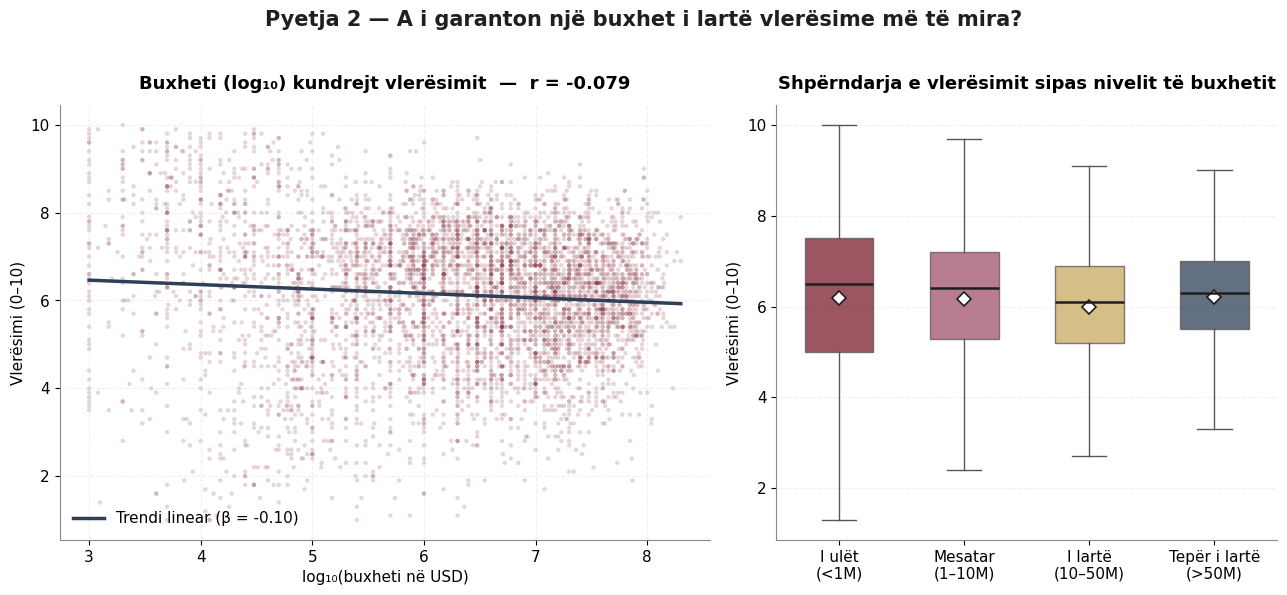

In [11]:
# Vizualizimi me dy panele
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8),
                         gridspec_kw={"width_ratios": [1.3, 1]})
fig.suptitle("Pyetja 2 — A i garanton një buxhet i lartë vlerësime më të mira?",
             fontsize=15, fontweight="bold", color=TEXT_DARK, y=1.02)

# 2a — Scatter plot me linjë regresi
ax = axes[0]
ax.scatter(sub_q2["log_budget"], sub_q2["rating"],
           s=10, alpha=0.18, color=PRIMARY, edgecolor="none")
# Llogarisim dhe vizatojmë linjën e regresit linear
coeffs = np.polyfit(sub_q2["log_budget"], sub_q2["rating"], 1)
xs = np.linspace(sub_q2["log_budget"].min(), sub_q2["log_budget"].max(), 50)
ax.plot(xs, np.polyval(coeffs, xs), color=ACCENT, linewidth=2.5,
        label=f"Trendi linear (β = {coeffs[0]:.2f})")
ax.set_title(f"Buxheti (log₁₀) kundrejt vlerësimit  —  r = {correlation:.3f}")
ax.set_xlabel("log₁₀(buxheti në USD)")
ax.set_ylabel("Vlerësimi (0–10)")
ax.legend(loc="lower left")
ax.grid(alpha=0.2, linestyle="--")

# 2b — Boxplot sipas kategorisë së buxhetit
ax = axes[1]
tiers = sub_q2["budget_tier"].cat.categories
box_data = [sub_q2.loc[sub_q2["budget_tier"] == t, "rating"].values for t in tiers]
bp = ax.boxplot(box_data, tick_labels=tiers, patch_artist=True,
                widths=0.55, showfliers=False,
                medianprops=dict(color=TEXT_DARK, linewidth=1.8),
                whiskerprops=dict(color=NEUTRAL),
                capprops=dict(color=NEUTRAL))
tier_colors = [PRIMARY, "#A0526D", SECONDARY, ACCENT]
for patch, c in zip(bp["boxes"], tier_colors):
    patch.set_facecolor(c); patch.set_alpha(0.75); patch.set_edgecolor(NEUTRAL)
# Shenja për mesataren në secilën kuti
for i, d in enumerate(box_data, start=1):
    ax.plot(i, np.mean(d), marker="D", color="white",
            markersize=7, markeredgecolor=TEXT_DARK, markeredgewidth=1.2)
ax.set_title("Shpërndarja e vlerësimit sipas nivelit të buxhetit")
ax.set_ylabel("Vlerësimi (0–10)")
ax.grid(axis="y", alpha=0.2, linestyle="--")

plt.tight_layout()
plt.show()

### Interpretimi i Pyetjes 2

* **Korrelacioni është statistikisht i pavlefshëm (r = -0.079).** Lidhja
  praktikisht **nuk ekziston** — madje është lehtësisht negative.
* **Mediana e vlerësimit ndryshon shumë pak** ndër kategori: 6.5 për filmat me
  buxhet të ulët, 6.1 për ata me buxhet të lartë (10–50M), 6.3 për blockbuster-ët.
  Pra, paratë **nuk blejnë vlerësime më të mira**.
* Shpërndarja e plotë (boxplot) tregon se filmat me buxhet të ulët kanë variancë
  më të madhe — ka edhe filma të shkëlqyer me 10/10 edhe filma të dështuar. Kjo
  ka kuptim: filmat e pavarur janë më të rrezikshëm, mund të prodhojnë gjenialitet
  ose dështim.
* **Përfundim:** "Më shumë para → film më i mirë" është një mit. Buxheti duket
  se është më shumë funksion i ambicies komerciale sesa cilësisë artistike.

## 8. Pyetja 3 — Cilët zhanre janë më të vlerësuar nga audienca?

**Pyetja e plotë:** Si ndryshon vlerësimi mesatar i audiencës nga njëri zhanër
te tjetri? A ka zhanre që sistematikisht marrin vlerësime më të larta?

**Kolonat e përfshira:** 7 flamuj të zhanrit (`Action`, `Animation`, `Comedy`,
`Drama`, `Documentary`, `Romance`, `Short`), `rating`, `votes`.

**Strategjia analitike:**

1. **Filtrojmë filma me ≥50 vota** për të garantuar besueshmëri statistikore
   (filmat me 5–10 vota nuk janë reprezentativë).
2. Llogarisim vlerësimin mesatar dhe medianën për çdo zhanër *veçmas*.
3. Vizualizojmë jo vetëm mesataren, por **shpërndarjen e plotë** (boxplot) që
   të shihet edhe varianca brenda zhanrit, jo vetëm prirja qendrore.

In [12]:
# Filtrim me të paktën 50 vota për të siguruar besueshmëri statistikore
df_rel = df[df["votes"] >= 50].copy()
print(f"Filma me ≥50 vota: {len(df_rel):,}")

# Llogarisim statistikat për secilin nga 7 zhanret
rows = []
for g in GENRE_COLS:
    s = df_rel.loc[df_rel[g] == 1, "rating"]
    rows.append({
        "genre":    g,
        "n_films":  len(s),
        "mean":     round(s.mean(),   3),
        "median":   round(s.median(), 3),
        "q25":      round(s.quantile(0.25), 3),
        "q75":      round(s.quantile(0.75), 3),
    })

genre_stats = pd.DataFrame(rows).sort_values("mean", ascending=True)
genre_stats

Filma me ≥50 vota: 22,713


,genre,n_films,mean,median,q25,q75
0,Action,2733,5.421,5.5,4.4,6.5
2,Comedy,7705,6.012,6.2,5.2,7.0
5,Romance,2795,6.308,6.4,5.7,7.1
3,Drama,10365,6.370,6.5,5.7,7.2
4,Documentary,722,6.922,7.2,6.5,7.7
1,Animation,817,6.967,7.2,6.5,7.7
6,Short,1179,7.057,7.2,6.6,7.7


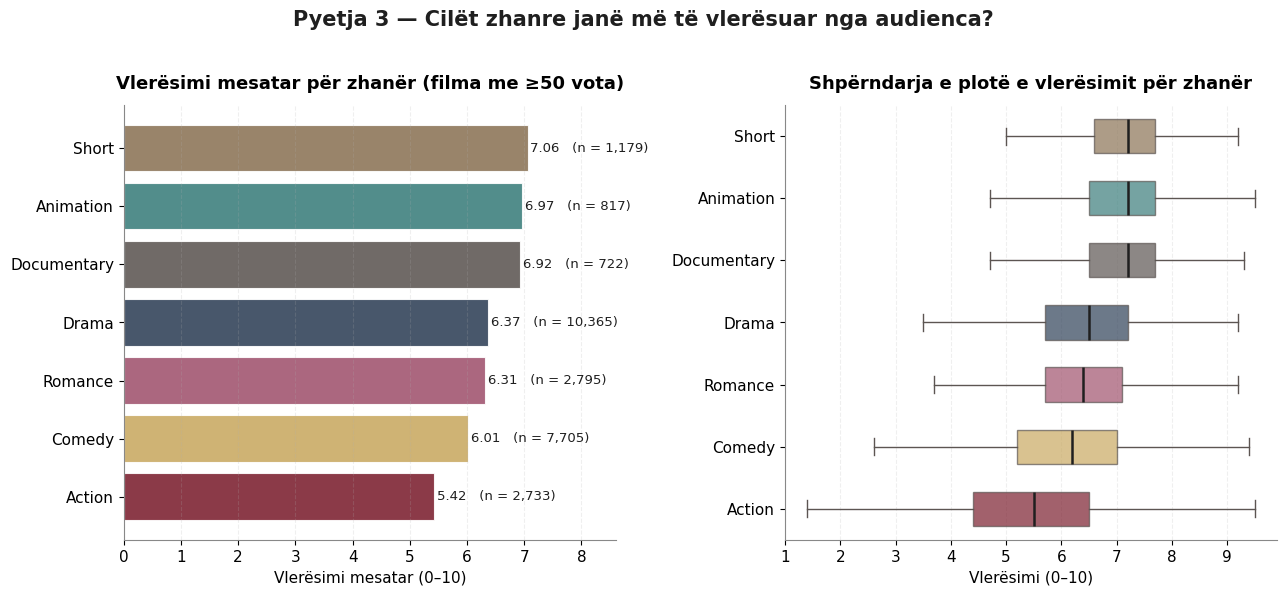

In [13]:
# Vizualizimi me dy panele: bar i renditur + boxplot i shpërndarjeve
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
fig.suptitle("Pyetja 3 — Cilët zhanre janë më të vlerësuar nga audienca?",
             fontsize=15, fontweight="bold", color=TEXT_DARK, y=1.02)

# 3a — bar horizontal me vlerësim mesatar
ax = axes[0]
bar_colors = [GENRE_PALETTE[g] for g in genre_stats["genre"]]
bars = ax.barh(genre_stats["genre"], genre_stats["mean"],
               color=bar_colors, alpha=0.88, edgecolor="white", linewidth=0.8)
for bar, val, n in zip(bars, genre_stats["mean"], genre_stats["n_films"]):
    ax.text(val + 0.05, bar.get_y() + bar.get_height() / 2,
            f"{val:.2f}   (n = {n:,})",
            va="center", fontsize=9.5, color=TEXT_DARK)
ax.set_xlim(0, 8.6)
ax.set_xlabel("Vlerësimi mesatar (0–10)")
ax.set_title("Vlerësimi mesatar për zhanër (filma me ≥50 vota)")
ax.grid(axis="x", alpha=0.2, linestyle="--")

# 3b — boxplot i shpërndarjes së plotë për çdo zhanër
ax = axes[1]
sorted_genres = genre_stats["genre"].tolist()
box_data = [df_rel.loc[df_rel[g] == 1, "rating"].values for g in sorted_genres]
bp = ax.boxplot(box_data, tick_labels=sorted_genres, patch_artist=True,
                widths=0.55, showfliers=False, vert=False,
                medianprops=dict(color=TEXT_DARK, linewidth=1.8),
                whiskerprops=dict(color=NEUTRAL),
                capprops=dict(color=NEUTRAL))
for patch, g in zip(bp["boxes"], sorted_genres):
    patch.set_facecolor(GENRE_PALETTE[g])
    patch.set_alpha(0.7); patch.set_edgecolor(NEUTRAL)
ax.set_xlabel("Vlerësimi (0–10)")
ax.set_title("Shpërndarja e plotë e vlerësimit për zhanër")
ax.grid(axis="x", alpha=0.2, linestyle="--")

plt.tight_layout()
plt.show()

### Interpretimi i Pyetjes 3

* **Filmat e shkurtër (Short), animacionet dhe dokumentarët marrin vlerësimet
  më të larta**, me mesatare mbi 6.9.
* **Filmat e veprimit (Action) janë në fund të listës (5.42).** Hipotezë:
  kjo nuk është domosdoshmërisht sepse janë "filma të këqij", por sepse
  *audienca e tyre është më e madhe dhe më kritike* — kur miliona shikues
  votojnë, mesatarja zbret natyrshëm drejt 5.
* **Drama dhe Romance janë në mes** (~6.3–6.4) — zhanre të qëndrueshme që as
  nuk thyejnë rekorde as nuk dështojnë rëndë.
* Boxplot-i tregon se Action ka **variancën më të madhe** (kuti më të gjerë),
  që do të thotë shumë filma të dështuar por edhe disa kryevepra (Die Hard,
  The Dark Knight Rises etj. nuk janë në këtë dataset që përfundon në 2005).
* **Përkujtim metodologjik:** këto janë mesatare *jo-ekskluzive*. Një film
  Action-Comedy futet në të dyja kategoritë.

## 9. Pyetja 4 — Cilët filma e ndajnë audiencën në kampe ekstreme?

**Pyetja e plotë:** Cilët janë filmat me audiencën më të polarizuar — domethënë
filma për të cilët një pjesë e audiencës jep 1/10 dhe një pjesë tjetër jep 10/10,
me pak vlerësime në mes? A ndryshojnë zhanret në polarizimin e tyre mesatar?

**Kolonat e përfshira:** `r1`, `r2`, `r5`, `r6`, `r9`, `r10`, `votes`, `title`,
`year`, plus 7 flamuj të zhanrit.

**Përkufizimi i indeksit të polarizimit:**

$$
\text{polarization} = \frac{r_1 + r_2 + r_9 + r_{10}}{r_5 + r_6 + 1}
$$

Sa më e madhe është kjo raport, aq më e ndarë është audienca midis "e urreje"
dhe "e adhuroj", me pak nga "ishte ok". Vlera +1 në emërues mbron kundër
pjesëtimit me zero.

**Strategjia analitike:**

1. Filtrojmë filma me ≥1000 vota (që indeksi të jetë i besueshëm).
2. Renditim sipas indeksit të polarizimit dhe shfaqim Top-15.
3. Llogarisim polarizimin mesatar për çdo zhanër.

In [14]:
# Filtër — minimum 1000 vota për besueshmëri statistikore të shpërndarjes
pol = df[df["votes"] >= 1000].copy()
print(f"Filma me ≥1000 vota: {len(pol):,}")

# Renditja sipas polarizimit dhe nxjerrja e Top-15
top15 = pol.sort_values("polarization", ascending=False).head(15).copy()
top15[["title", "year", "rating", "votes", "polarization"]].round(2)

Filma me ≥1000 vota: 4,515


,title,year,rating,votes,polarization
49982,SuperBabies: Baby Geniuses 2,2004,1.8,2224,10.8
34,'Manos' the Hands of Fate,1966,1.6,7996,9.8
4009,Backyard Dogs,2000,1.9,1304,9.8
53368,Troll 2,1990,1.8,1952,9.8
12399,Daniel - Der Zauberer,2004,1.8,2698,9.8
44763,Santa with Muscles,1996,1.8,2612,9.8
36356,Night Train to Mundo Fine,1966,1.8,1095,9.8
32292,Maratonci trce pocasni krug,1982,8.4,1388,9.8
5879,Black,2005,8.4,1013,9.8
19134,From Justin to Kelly,2003,1.7,6517,9.8


In [15]:
# Polarizimi mesatar për zhanër
rows = []
for g in GENRE_COLS:
    s = pol.loc[pol[g] == 1, "polarization"]
    if len(s) > 0:
        rows.append({"genre": g,
                     "mean_pol": round(s.mean(), 3),
                     "n_films": len(s)})

pol_by_genre = pd.DataFrame(rows).sort_values("mean_pol", ascending=True)
pol_by_genre

,genre,mean_pol,n_films
0,Action,1.891,890
2,Comedy,2.002,1845
5,Romance,2.398,884
3,Drama,2.729,2371
1,Animation,2.752,135
4,Documentary,4.370,53
6,Short,5.805,20


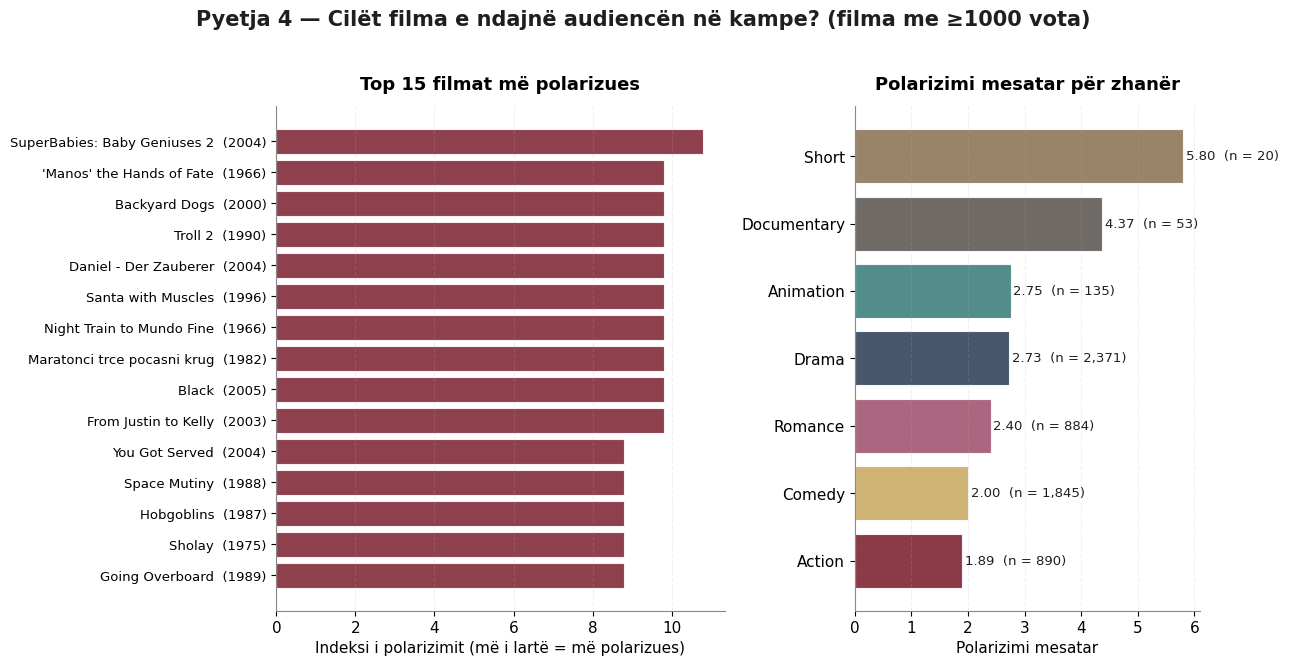

In [16]:
# Vizualizimi me dy panele
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5),
                         gridspec_kw={"width_ratios": [1.3, 1]})
fig.suptitle("Pyetja 4 — Cilët filma e ndajnë audiencën në kampe? "
             "(filma me ≥1000 vota)",
             fontsize=15, fontweight="bold", color=TEXT_DARK, y=1.02)

# 4a — Top 15 filmat më polarizues
ax = axes[0]
labels = [f"{t[:34]}{'…' if len(t) > 34 else ''}  ({int(y)})"
          for t, y in zip(top15["title"], top15["year"])]
ax.barh(range(len(top15)), top15["polarization"][::-1],
        color=PRIMARY, alpha=0.85, edgecolor="white", linewidth=0.8)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(labels[::-1], fontsize=9.5)
ax.set_xlabel("Indeksi i polarizimit (më i lartë = më polarizues)")
ax.set_title("Top 15 filmat më polarizues")
ax.grid(axis="x", alpha=0.2, linestyle="--")

# 4b — Polarizimi mesatar për zhanër
ax = axes[1]
bar_colors = [GENRE_PALETTE[g] for g in pol_by_genre["genre"]]
bars = ax.barh(pol_by_genre["genre"], pol_by_genre["mean_pol"],
               color=bar_colors, alpha=0.88, edgecolor="white", linewidth=0.8)
for bar, val, n in zip(bars, pol_by_genre["mean_pol"], pol_by_genre["n_films"]):
    ax.text(val + 0.05, bar.get_y() + bar.get_height() / 2,
            f"{val:.2f}  (n = {n:,})",
            va="center", fontsize=9.5, color=TEXT_DARK)
ax.set_xlabel("Polarizimi mesatar")
ax.set_title("Polarizimi mesatar për zhanër")
ax.grid(axis="x", alpha=0.2, linestyle="--")

plt.tight_layout()
plt.show()

### Interpretimi i Pyetjes 4

* **Filmat më polarizues janë në shumicë "cult-bad"** — vepra që kanë vlerësim
  mesatar shumë të ulët por kanë një grup të vogël adhuruesish të zjarrtë.
  Shembuj: *Troll 2* (1990), *Manos: The Hands of Fate* (1966), *SuperBabies:
  Baby Geniuses 2* (2004). Këta janë filma të njohur si më të këqijtë e të
  gjitha kohërave, por janë ndjekur nga komunitete kult.
* Polarizimi i lartë **nuk** do të thotë "film i mirë i diskutueshëm". Do të
  thotë "film që një pakicë vocale e mbron edhe pse shumica e refuzon".
* **Shorts dhe Documentary janë zhanret më polarizues** (5.80 dhe 4.37) — kjo
  ka kuptim sepse janë formate "nikë" që tërheqin ose adhurues të mëdhenj ose
  refuzues të menjëhershëm.
* **Action dhe Comedy janë më të paqarta** (≈2.0) — audienca e tyre është
  masive dhe rrjedhimisht më e centruar drejt 5–7.

## 10. Konkluzionet e përmbledhura

Analiza e dataset-it IMDb Movies (58,788 filma, 1893–2005) zbuloi katër
gjetje kryesore:

1. **Industria u rrit në mënyrë eksponenciale pas vitit 1980** — nga ~7,900
   filma në dekadën '80 në mbi 12,700 në vitet '90. Buxhetet ndoqën të njëjtin
   trend rritjeje, ndërsa kohëzgjatja arriti maksimumin rreth vitit 1980
   (~95 min) dhe pastaj u shkurtua.

2. **Buxheti i lartë nuk siguron cilësi më të lartë.** Korrelacioni midis
   log(buxhetit) dhe vlerësimit është praktikisht zero (r = -0.079). Filmat me
   buxhet >$50M nuk vlerësohen më mirë se ata <$1M.

3. **Format e specializuara dominojnë vlerësimet:** filmat e shkurtër,
   animacionet dhe dokumentarët marrin vlerësime mesatare mbi 6.9, ndërsa
   Action-i është më i ulëti me 5.4 — i ndikuar nga audiencë masive dhe më
   kritike.

4. **Filmat më polarizues janë "kult-bad" filma**, jo kryevepra të diskutueshme.
   Shorts dhe Documentary janë zhanret më polarizues si format; Action dhe
   Comedy janë më të qartë në vlerësim.

### Kufizimet e analizës

* Dataset-i përfundon në vitin 2005 — filmat modernë (epoka e Marvel-it,
  streaming-ut etj.) nuk janë të mbuluar.
* Mungesa masive e të dhënave të buxhetit (~91%) e kufizon analizën financiare
  vetëm te ~5,200 rekorde.
* Audienca votuese e IMDb nuk është reprezentative e popullsisë së përgjithshme:
  ka tendencë drejt të rinjve, meshkujve dhe entuziastëve të kinemasë.

---

## 11. Referencat

1. Wickham, H. (2016). *ggplot2: Elegant Graphics for Data Analysis*. Springer-Verlag
   New York. ISBN 978-3-319-24277-4. (Paketa origjinale e dataset-it `movies`.)

2. Wickham, H. (2008). *Movies dataset (ggplot2movies)*. CRAN.
   <https://cran.r-project.org/package=ggplot2movies>

3. Internet Movie Database (IMDb), <https://www.imdb.com> — burimi origjinal i
   të dhënave të agreguara.

4. McKinney, W. (2010). "Data Structures for Statistical Computing in Python."
   *Proceedings of the 9th Python in Science Conference*, 56–61.
   (Biblioteka pandas.)

5. Hunter, J. D. (2007). "Matplotlib: A 2D graphics environment."
   *Computing in Science & Engineering*, 9(3), 90–95.